# Extension: impact of multipath richness on CSI-based localization
Same users, same gNB (t006), same split, same models and training; only the number of
propagation paths kept in the CSI changes:
- **1 path**: strongest path only (direct, LoS) - an artificial "no reflections" channel,
- **3 paths**: direct + the two strongest reflections,
- **18 paths**: every path stored by DeepMIMO (the realistic channel used in the main study).

Input representation: real / imaginary (best in the main study). Models: CNN baseline and ViT.

**Colab:** Runtime > Change runtime type > T4 GPU. Upload the three .mat files and set `DATA_DIR`.
Runtime on a T4: ~20 min per seed (3 datasets x CNN + ViT). `SEEDS = [0]` ~20 min, `[0, 1, 2]` ~60 min.

## 1. Setup and settings

In [1]:
import os, sys, time, json
import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from scipy.io import loadmat

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    DATA_DIR = '/content'                   # <- folder holding the three .mat files
    OUT_DIR  = '/content/csi_multipath'
else:
    DATA_DIR, OUT_DIR = '.', 'results_multipath'
FILES = {1: 'csi_o1_1path.mat', 3: 'csi_o1_3paths.mat', 18: 'csi_o1_18paths.mat'}
FIG_DIR = os.path.join(OUT_DIR, 'figs'); os.makedirs(FIG_DIR, exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '| outputs ->', OUT_DIR)

PATHS   = [1, 3, 18]
MODELS  = ['CNN', 'ViT']
SEEDS   = [0, 1, 2]           # [0] for a ~20 min run
BLOCK_M = 10
EPOCHS  = {'CNN': 40, 'ViT': 60}
LR      = {'CNN': 2e-3, 'ViT': 1e-3}
BATCH   = 256
FAST    = False               # True: 2 epochs, one seed (crash test)
if FAST:
    EPOCHS, SEEDS = {'CNN': 3, 'ViT': 3}, [0]

P_COL = {1: '#d62728', 3: '#ff7f0e', 18: '#2ca02c'}      # colour per dataset
M_LS  = {'CNN': '--', 'ViT': '-'}                         # line style per model
def tag(p): return f'{p} path' + ('' if p == 1 else 's')

def seed_all(s):
    torch.manual_seed(s); np.random.seed(s)
    if device == 'cuda': torch.cuda.manual_seed_all(s)

def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches='tight'); plt.show()

device: cuda | outputs -> /content/csi_multipath


## 2. Load the three datasets and check they describe the same users

In [2]:
DS = {}
for p in PATHS:
    d = loadmat(os.path.join(DATA_DIR, FILES[p]))
    DS[p] = dict(H=d['H'].astype(np.complex64), pos=d['pos'].astype(np.float32)[:, :2])
    print(f'{tag(p):9s}: H {DS[p]["H"].shape}')
bs  = d['bs_pos'].ravel()[:2]
pos = DS[18]['pos']
for p in PATHS:
    assert DS[p]['H'].shape == DS[18]['H'].shape, 'datasets have different sizes'
    assert np.allclose(DS[p]['pos'], pos), f'{tag(p)}: users differ from the 18-path dataset'
print('Same 30k users in all three datasets. gNB at', bs)
N = len(pos)

1 path   : H (30000, 32, 32)
3 paths  : H (30000, 32, 32)
18 paths : H (30000, 32, 32)
Same 30k users in all three datasets. gNB at [287.5039978  589.50402832]


## 3. Spatial split (identical for the three datasets)

In [3]:
block = np.floor((pos[:, 1] - pos[:, 1].min()) / BLOCK_M).astype(int)
split = np.full(N, 'train', dtype=object)
split[block % 5 == 2] = 'test'; split[block % 5 == 4] = 'val'
idx = {s: np.where(split == s)[0] for s in ['train', 'val', 'test']}
print({s: len(v) for s, v in idx.items()})
POS_MEAN = pos[idx['train']].mean(0); POS_STD = pos[idx['train']].std(0)
dist = np.hypot(pos[:, 0] - bs[0], pos[:, 1] - bs[1])     # distance to the gNB (m)

def to_target(p):   return torch.from_numpy((p - POS_MEAN) / POS_STD)
def from_target(t): return t * POS_STD + POS_MEAN
Y = {s: to_target(pos[i]) for s, i in idx.items()}

# Re/Im input, global scale computed on each dataset's training set
SCALE, X = {}, {}
def encode(Hc, p):
    Hn = Hc / SCALE[p]
    return torch.from_numpy(np.stack([Hn.real, Hn.imag], 1).astype(np.float32))
for p in PATHS:
    SCALE[p] = float(np.sqrt(np.mean(np.abs(DS[p]['H'][idx['train']]) ** 2)))
    X[p] = {s: encode(DS[p]['H'][i], p) for s, i in idx.items()}

{'train': 17947, 'val': 5990, 'test': 6063}


## 4. What multipath does to the CSI (same two users, three datasets)

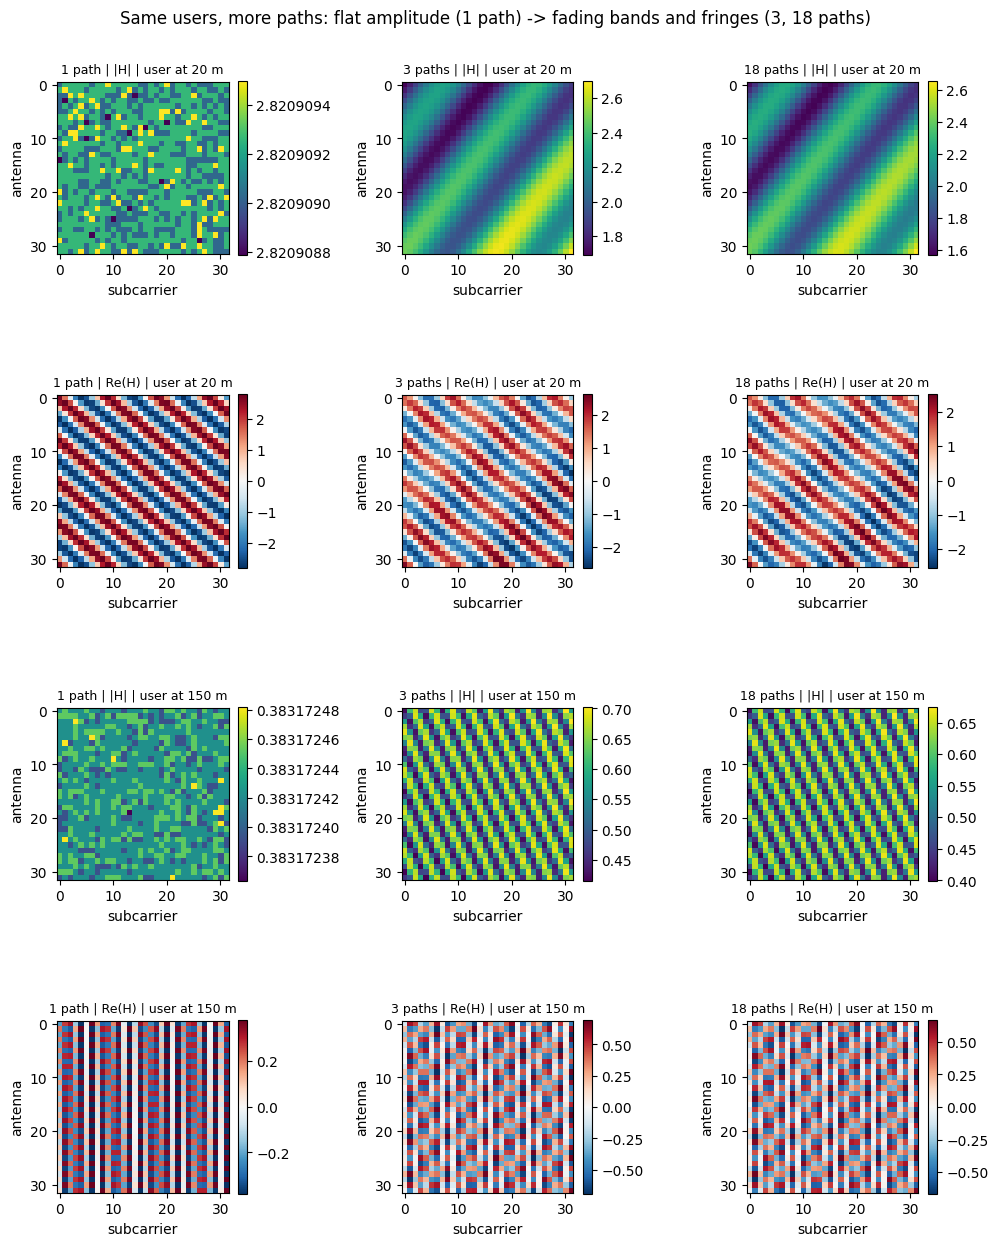

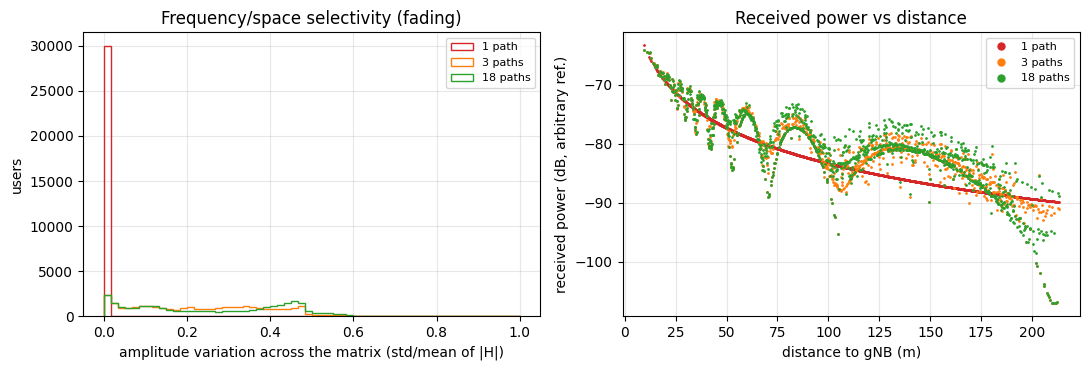

In [4]:
users = [int(np.argmin(np.abs(dist - 20))), int(np.argmin(np.abs(dist - 150)))]
fig, axs = plt.subplots(4, 3, figsize=(10, 13))
for c, p in enumerate(PATHS):
    for r, (u, kind) in enumerate([(users[0], 'abs'), (users[0], 're'), (users[1], 'abs'), (users[1], 're')]):
        h = DS[p]['H'][u] / SCALE[p]
        img, cmap = (np.abs(h), 'viridis') if kind == 'abs' else (h.real, 'RdBu_r')
        im = axs[r, c].imshow(img, cmap=cmap, aspect='equal')
        cb = fig.colorbar(im, ax=axs[r, c], fraction=0.046); cb.formatter.set_useOffset(False); cb.update_ticks()
        axs[r, c].set_title(f"{tag(p)} | {'|H|' if kind == 'abs' else 'Re(H)'} | user at {dist[u]:.0f} m", fontsize=9)
        axs[r, c].set_xlabel('subcarrier'); axs[r, c].set_ylabel('antenna')
fig.suptitle('Same users, more paths: flat amplitude (1 path) -> fading bands and fringes (3, 18 paths)')
savefig('mp_csi_images.png')

# Channel "richness": how much the amplitude varies across the 32x32 matrix (0 = perfectly flat)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for p in PATHS:
    a = np.abs(DS[p]['H'])
    cv = (a.std(axis=(1, 2)) / a.mean(axis=(1, 2)))
    rx = 10 * np.log10(np.mean(np.abs(DS[p]['H']) ** 2, axis=(1, 2)))
    axs[0].hist(cv, bins=60, range=(0, max(1.0, np.percentile(cv, 99.5))), histtype='step', lw=2, color=P_COL[p], label=tag(p))
    order = np.argsort(dist)
    axs[1].plot(dist[order][::25], rx[order][::25], '.', ms=2, color=P_COL[p], label=tag(p))
axs[0].set_xlabel('amplitude variation across the matrix (std/mean of |H|)'); axs[0].set_ylabel('users')
axs[0].set_title('Frequency/space selectivity (fading)')
axs[1].set_xlabel('distance to gNB (m)'); axs[1].set_ylabel('received power (dB, arbitrary ref.)')
axs[1].set_title('Received power vs distance')
for a in axs: a.grid(alpha=.3); a.legend(fontsize=8, markerscale=5)
savefig('mp_channel_stats.png')

## 5. Models (same as the main study)

In [5]:
class CNN(nn.Module):
    def __init__(self, in_ch=2):
        super().__init__()
        def blk(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                                            nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU())
        self.f = nn.Sequential(blk(in_ch, 32), nn.MaxPool2d(2), blk(32, 64), nn.MaxPool2d(2),
                               blk(64, 128), nn.AdaptiveAvgPool2d(1))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(128, 128), nn.ReLU(), nn.Dropout(0.1), nn.Linear(128, 2))
    def forward(self, x): return self.head(self.f(x))

class ViT(nn.Module):
    def __init__(self, in_ch=2, n_ant=32, n_sub=32, pa=4, ps=4, dim=128, depth=4, heads=4, mlp=256, drop=0.1):
        super().__init__()
        self.patch = nn.Conv2d(in_ch, dim, kernel_size=(pa, ps), stride=(pa, ps))
        self.pos_ant = nn.Parameter(torch.zeros(1, dim, n_ant // pa, 1))
        self.pos_sub = nn.Parameter(torch.zeros(1, dim, 1, n_sub // ps))
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))
        for q in (self.pos_ant, self.pos_sub, self.cls): nn.init.trunc_normal_(q, std=.02)
        layer = nn.TransformerEncoderLayer(dim, heads, mlp, drop, activation='gelu', batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(dim); self.head = nn.Linear(dim, 2)
    def forward(self, x):
        z = (self.patch(x) + self.pos_ant + self.pos_sub).flatten(2).transpose(1, 2)
        z = torch.cat([self.cls.expand(len(z), -1, -1), z], 1)
        return self.head(self.norm(self.enc(z)[:, 0]))

BUILD = {'CNN': CNN, 'ViT': ViT}

## 6. Training / evaluation helpers

In [6]:
def predict(model, Xs, bs=2048):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(Xs), bs):
            out.append(model(Xs[i:i + bs].to(device)).cpu())
    return torch.cat(out).numpy()

def errors_m(model, Xs, true_pos):
    return np.linalg.norm(from_target(predict(model, Xs)) - true_pos, axis=1)

def train(name, arch, Xtr, Ytr, Xval, pos_val, epochs, lr, seed):
    seed_all(seed)
    model = BUILD[arch]().to(device); Xtr, Ytr = Xtr.to(device), Ytr.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * int(np.ceil(len(Xtr) / BATCH)), pct_start=0.1)
    loss_fn = nn.SmoothL1Loss(beta=0.05)
    best, best_state, hist, t0 = 1e9, None, [], time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(Xtr), BATCH):
            b = perm[i:i + BATCH]
            loss = loss_fn(model(Xtr[b]), Ytr[b])
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        val_err = errors_m(model, Xval, pos_val).mean(); hist.append(val_err)
        if val_err < best:
            best, best_state = val_err, {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    print(f'[{name}] {time.time()-t0:.0f}s | best val mean err {best:.2f} m')
    return model, np.array(hist)

def summary(e):
    return dict(mean=float(e.mean()), median=float(np.median(e)), p90=float(np.percentile(e, 90)),
                rmse=float(np.sqrt((e ** 2).mean())), gross_pct=float(100 * (e > 50).mean()))

## 7. Train: 3 datasets x 2 models x seeds

In [7]:
runs = {}
for p in PATHS:
    for arch in MODELS:
        for s in SEEDS:
            m, h = train(f'{tag(p)} {arch} seed{s}', arch, X[p]['train'], Y['train'], X[p]['val'],
                         pos[idx['val']], EPOCHS[arch], LR[arch], s)
            runs[(p, arch, s)] = dict(model=m, hist=h, err=errors_m(m, X[p]['test'], pos[idx['test']]))
s0 = SEEDS[0]

[1 path CNN seed0] 97s | best val mean err 6.62 m
[1 path CNN seed1] 98s | best val mean err 7.15 m
[1 path CNN seed2] 98s | best val mean err 6.06 m
[1 path ViT seed0] 267s | best val mean err 6.80 m
[1 path ViT seed1] 266s | best val mean err 6.60 m
[1 path ViT seed2] 267s | best val mean err 7.41 m
[3 paths CNN seed0] 98s | best val mean err 6.18 m
[3 paths CNN seed1] 98s | best val mean err 5.97 m
[3 paths CNN seed2] 99s | best val mean err 5.49 m
[3 paths ViT seed0] 268s | best val mean err 4.78 m
[3 paths ViT seed1] 267s | best val mean err 5.78 m
[3 paths ViT seed2] 267s | best val mean err 4.63 m
[18 paths CNN seed0] 98s | best val mean err 7.20 m
[18 paths CNN seed1] 99s | best val mean err 8.09 m
[18 paths CNN seed2] 99s | best val mean err 6.25 m
[18 paths ViT seed0] 267s | best val mean err 3.73 m
[18 paths ViT seed1] 267s | best val mean err 4.57 m
[18 paths ViT seed2] 267s | best val mean err 4.34 m


## 8. Results table (mean +- std over seeds)

In [8]:
res = {}
print(f"{'dataset':9s} {'model':5s} {'mean (m)':>14s} {'median (m)':>14s} {'P90 (m)':>14s} {'RMSE (m)':>14s} {'>50 m (%)':>12s}")
for p in PATHS:
    for arch in MODELS:
        S = [summary(runs[(p, arch, s)]['err']) for s in SEEDS]
        agg = {k: (float(np.mean([x[k] for x in S])), float(np.std([x[k] for x in S]))) for k in S[0]}
        res[(p, arch)] = agg
        f = lambda k: f"{agg[k][0]:6.2f} ± {agg[k][1]:4.2f}"
        print(f"{tag(p):9s} {arch:5s} {f('mean'):>14s} {f('median'):>14s} {f('p90'):>14s} {f('rmse'):>14s} {f('gross_pct'):>12s}")

dataset   model       mean (m)     median (m)        P90 (m)       RMSE (m)    >50 m (%)
1 path    CNN      5.63 ± 0.41    2.53 ± 0.36    7.38 ± 1.54   18.25 ± 4.54   1.74 ± 0.39
1 path    ViT      2.23 ± 0.65    1.47 ± 0.37    3.74 ± 0.49    8.16 ± 4.94   0.15 ± 0.12
3 paths   CNN     10.17 ± 0.49    2.50 ± 0.19    6.67 ± 0.19   47.47 ± 3.16   2.55 ± 0.04
3 paths   ViT      6.46 ± 0.98    1.51 ± 0.23    4.21 ± 0.31   39.06 ± 4.58   1.41 ± 0.23
18 paths  CNN      4.43 ± 0.35    2.48 ± 0.23    6.30 ± 0.60   18.33 ± 0.63   0.68 ± 0.03
18 paths  ViT      2.89 ± 0.44    1.64 ± 0.13    4.05 ± 0.08   14.63 ± 4.86   0.35 ± 0.18


## 9. Main comparison: median / P90 / mean vs number of paths

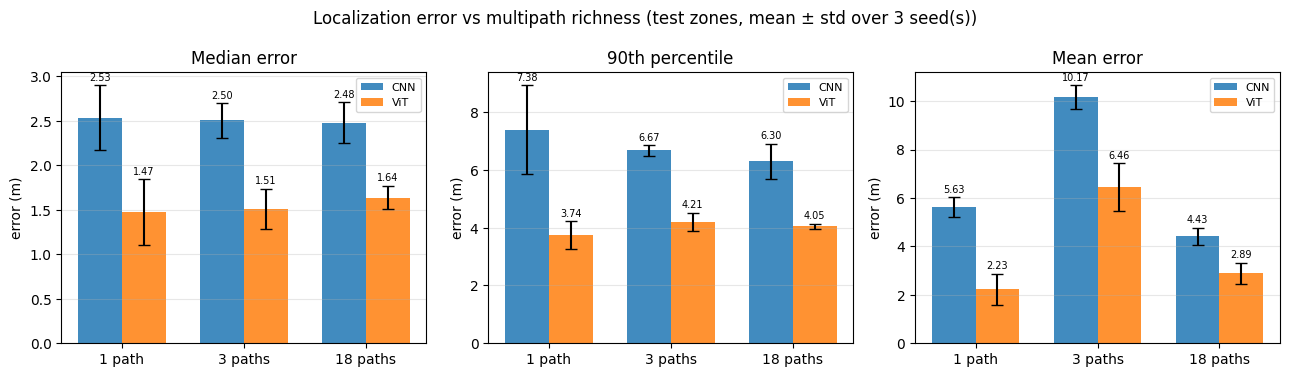

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
xs = np.arange(len(PATHS)); w = 0.36
for ax, k, title in zip(axs, ['median', 'p90', 'mean'], ['Median error', '90th percentile', 'Mean error']):
    for j, arch in enumerate(MODELS):
        v = [res[(p, arch)][k][0] for p in PATHS]; e = [res[(p, arch)][k][1] for p in PATHS]
        bars = ax.bar(xs + (j - 0.5) * w, v, w, yerr=e, capsize=4, label=arch,
                      color=['tab:blue', 'tab:orange'][j], alpha=0.85)
        ax.bar_label(bars, fmt='%.2f', fontsize=7, padding=2)
    ax.set_xticks(xs, [tag(p) for p in PATHS]); ax.set_ylabel('error (m)'); ax.set_title(title)
    ax.grid(axis='y', alpha=.3); ax.legend(fontsize=8)
fig.suptitle(f'Localization error vs multipath richness (test zones, mean ± std over {len(SEEDS)} seed(s))')
savefig('mp_errors_vs_paths.png')

## 10. CDFs

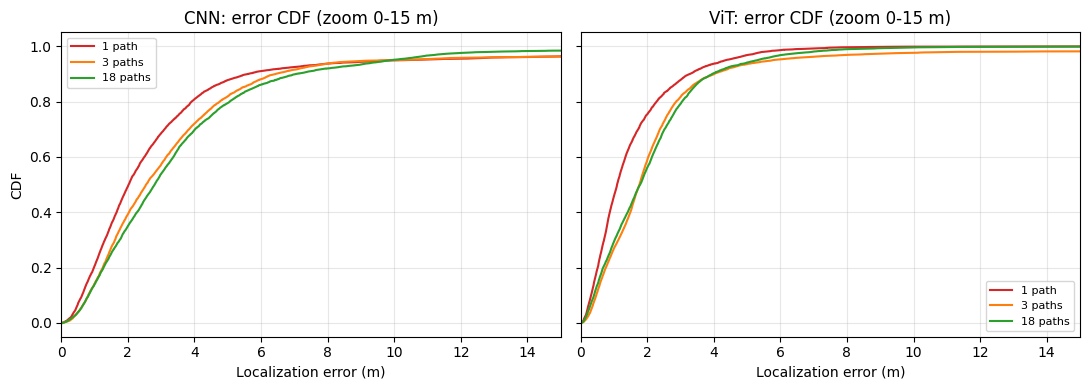

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, arch in zip(axs, MODELS):
    for p in PATHS:
        e = np.sort(runs[(p, arch, s0)]['err'])
        ax.plot(e, np.arange(1, len(e) + 1) / len(e), color=P_COL[p], label=tag(p))
    ax.set_xlim(0, 15); ax.set_xlabel('Localization error (m)'); ax.set_title(f'{arch}: error CDF (zoom 0-15 m)')
    ax.grid(alpha=.3); ax.legend(fontsize=8)
axs[0].set_ylabel('CDF')
savefig('mp_cdf.png')

## 11. Where does multipath help? Median error vs distance to the gNB

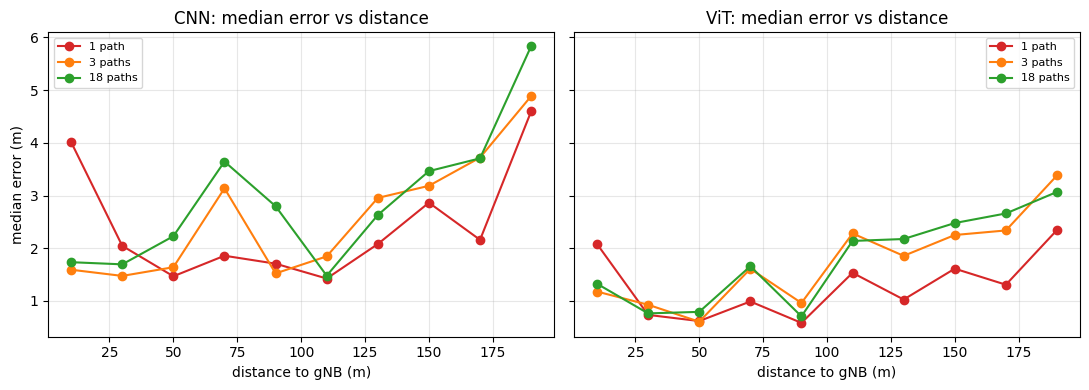

In [11]:
bins = np.arange(0, 220, 20); centers = (bins[:-1] + bins[1:]) / 2
dt = dist[idx['test']]
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, arch in zip(axs, MODELS):
    for p in PATHS:
        e = runs[(p, arch, s0)]['err']
        med = [np.median(e[(dt >= lo) & (dt < hi)]) if ((dt >= lo) & (dt < hi)).sum() > 20 else np.nan
               for lo, hi in zip(bins[:-1], bins[1:])]
        ax.plot(centers, med, 'o-', color=P_COL[p], label=tag(p))
    ax.set_xlabel('distance to gNB (m)'); ax.set_title(f'{arch}: median error vs distance'); ax.grid(alpha=.3); ax.legend(fontsize=8)
axs[0].set_ylabel('median error (m)')
savefig('mp_error_vs_distance.png')

## 12. Error maps (seed 0)

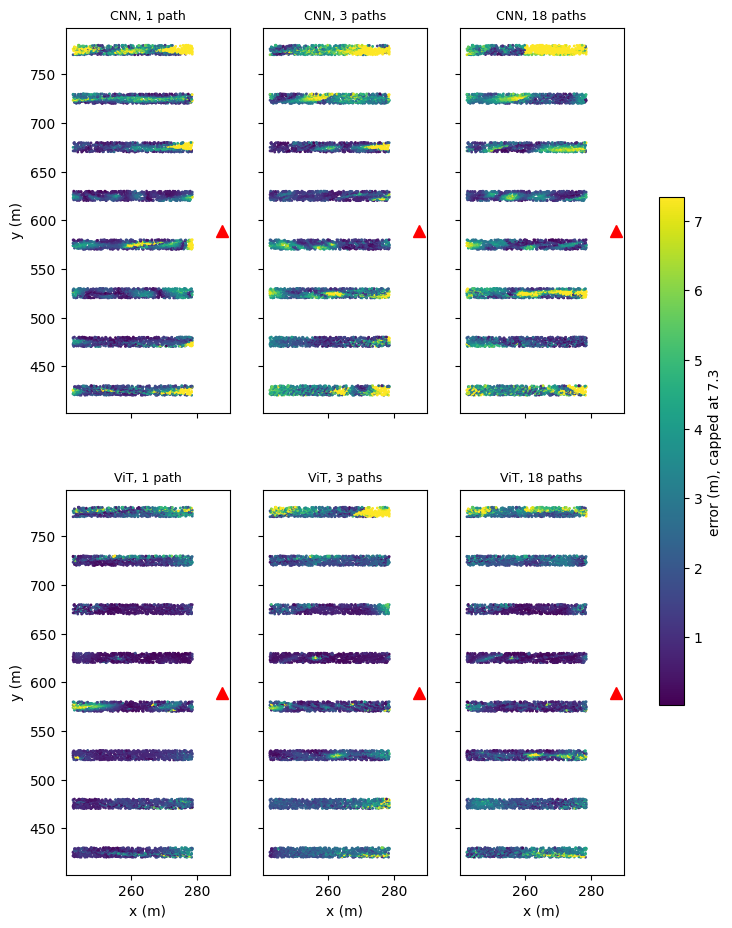

In [12]:
vmax = np.percentile(np.concatenate([runs[(p, a, s0)]['err'] for p in PATHS for a in MODELS]), 95)
fig, axs = plt.subplots(2, 3, figsize=(9, 11), sharex=True, sharey=True)
for r, arch in enumerate(MODELS):
    for c, p in enumerate(PATHS):
        sc = axs[r, c].scatter(pos[idx['test'], 0], pos[idx['test'], 1], c=runs[(p, arch, s0)]['err'], s=1, cmap='viridis', vmax=vmax)
        axs[r, c].plot(*bs, 'r^', ms=8); axs[r, c].set_title(f'{arch}, {tag(p)}', fontsize=9)
for a in axs[-1]: a.set_xlabel('x (m)')
for a in axs[:, 0]: a.set_ylabel('y (m)')
fig.colorbar(sc, ax=axs, label=f'error (m), capped at {vmax:.1f}', shrink=0.6)
plt.savefig(os.path.join(FIG_DIR, 'mp_error_maps.png'), dpi=200, bbox_inches='tight'); plt.show()

## 13. Gross errors and north/south mirror confusions (seed 0)

1 path    CNN: 128 errors > 50 m (2.11%), 34% on the wrong side of the gNB
1 path    ViT:   1 errors > 50 m (0.02%), 0% on the wrong side of the gNB
3 paths   CNN: 156 errors > 50 m (2.57%), 81% on the wrong side of the gNB
3 paths   ViT: 104 errors > 50 m (1.72%), 91% on the wrong side of the gNB
18 paths  CNN:  43 errors > 50 m (0.71%), 56% on the wrong side of the gNB
18 paths  ViT:   7 errors > 50 m (0.12%), 57% on the wrong side of the gNB


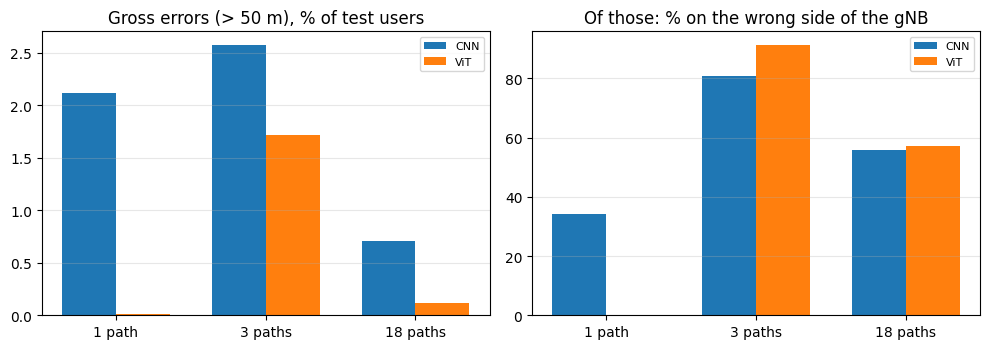

In [13]:
gross = {}
for p in PATHS:
    for arch in MODELS:
        m = runs[(p, arch, s0)]['model']; e = runs[(p, arch, s0)]['err']; bad = e > 50
        pred = from_target(predict(m, X[p]['test'])); true = pos[idx['test']]
        mirror = float(100 * (np.sign(pred[bad, 1] - bs[1]) != np.sign(true[bad, 1] - bs[1])).mean()) if bad.any() else 0.0
        gross[(p, arch)] = dict(pct=float(100 * bad.mean()), mirror_pct=mirror)
        print(f'{tag(p):9s} {arch}: {bad.sum():3d} errors > 50 m ({100*bad.mean():.2f}%), {mirror:.0f}% on the wrong side of the gNB')
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
for j, arch in enumerate(MODELS):
    axs[0].bar(xs + (j - 0.5) * w, [gross[(p, arch)]['pct'] for p in PATHS], w, label=arch, color=['tab:blue', 'tab:orange'][j])
    axs[1].bar(xs + (j - 0.5) * w, [gross[(p, arch)]['mirror_pct'] for p in PATHS], w, label=arch, color=['tab:blue', 'tab:orange'][j])
axs[0].set_title('Gross errors (> 50 m), % of test users'); axs[1].set_title('Of those: % on the wrong side of the gNB')
for a in axs: a.set_xticks(xs, [tag(p) for p in PATHS]); a.grid(axis='y', alpha=.3); a.legend(fontsize=8)
savefig('mp_gross_errors.png')

## 14. Robustness to noise (test-time AWGN, seed 0)

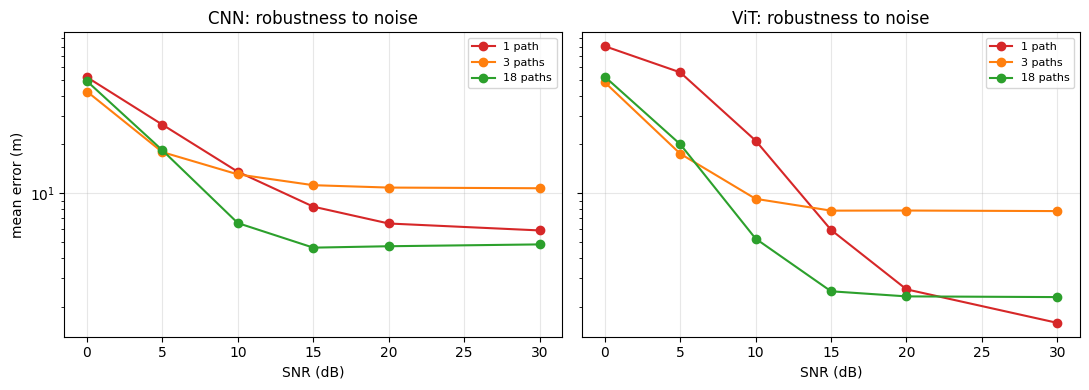

In [14]:
SNRS = [0, 5, 10, 15, 20, 30]
snr_res = {}
for p in PATHS:
    rng = np.random.default_rng(0)
    Ht = DS[p]['H'][idx['test']]; p_sig = np.mean(np.abs(Ht) ** 2, axis=(1, 2), keepdims=True)
    for arch in MODELS: snr_res[(p, arch)] = []
    for snr in SNRS:
        noise = (rng.standard_normal(Ht.shape) + 1j * rng.standard_normal(Ht.shape)) / np.sqrt(2)
        Xn = encode((Ht + np.sqrt(p_sig / 10 ** (snr / 10)) * noise).astype(np.complex64), p)
        for arch in MODELS:
            snr_res[(p, arch)].append(float(errors_m(runs[(p, arch, s0)]['model'], Xn, pos[idx['test']]).mean()))
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, arch in zip(axs, MODELS):
    for p in PATHS:
        ax.plot(SNRS, snr_res[(p, arch)], 'o-', color=P_COL[p], label=tag(p))
    ax.set_yscale('log'); ax.set_xlabel('SNR (dB)'); ax.set_title(f'{arch}: robustness to noise'); ax.grid(alpha=.3); ax.legend(fontsize=8)
axs[0].set_ylabel('mean error (m)')
savefig('mp_snr.png')

## 15. Learning curves (seed 0)

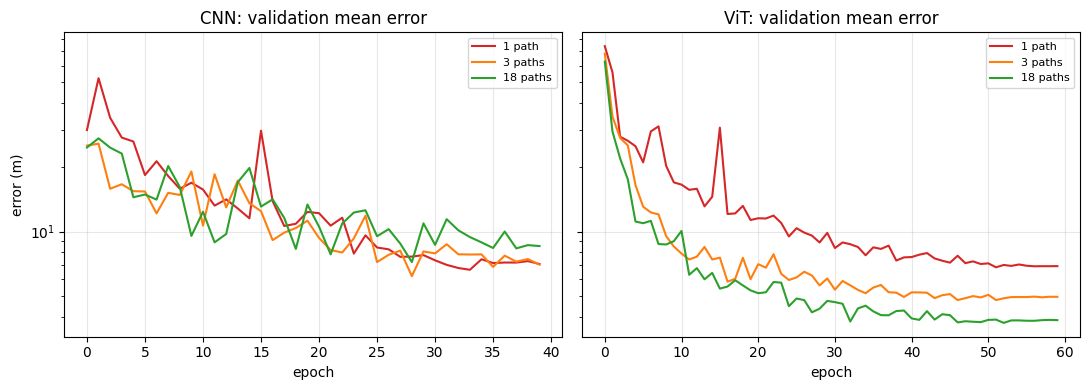

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, arch in zip(axs, MODELS):
    for p in PATHS:
        ax.plot(runs[(p, arch, s0)]['hist'], color=P_COL[p], label=tag(p))
    ax.set_yscale('log'); ax.set_xlabel('epoch'); ax.set_title(f'{arch}: validation mean error'); ax.grid(alpha=.3); ax.legend(fontsize=8)
axs[0].set_ylabel('error (m)')
savefig('mp_learning_curves.png')

## 16. Save

In [16]:
out = dict(config=dict(files=FILES, seeds=SEEDS, epochs=EPOCHS, lr=LR, input='re_im', device=device,
                       split={s: int(len(v)) for s, v in idx.items()}),
           results={f'{p}/{a}': v for (p, a), v in res.items()},
           gross_errors={f'{p}/{a}': v for (p, a), v in gross.items()},
           snr_db=SNRS, snr_mean_err={f'{p}/{a}': v for (p, a), v in snr_res.items()})
with open(os.path.join(OUT_DIR, 'results_multipath.json'), 'w') as fh:
    json.dump(out, fh, indent=2)
print('Saved results_multipath.json and figures to', OUT_DIR)

Saved results_multipath.json and figures to /content/csi_multipath
